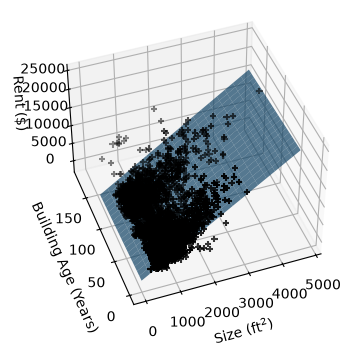

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

streeteasy = pd.read_csv("streeteasy.csv")

df = pd.DataFrame(streeteasy)

x = df[['size_sqft','building_age_yrs']]
y = df[['rent']]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.8, test_size=0.2, random_state=6
)

ols = LinearRegression()
ols.fit(x_train, y_train)

# --- Plot ---
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(111, projection='3d')

# Set view
ax.view_init(elev=43.5, azim=-110)

# Scatter points
ax.scatter(
    x_train['size_sqft'],
    x_train['building_age_yrs'],
    y_train['rent'],
    c='k', marker='+'
)

# Build a grid for the regression plane
x_surf = np.linspace(0, 4500, 20)
y_surf = np.linspace(0, 140, 20)
xx, yy = np.meshgrid(x_surf, y_surf)

# Create a DataFrame with correct feature names
grid = pd.DataFrame({
    'size_sqft': xx.ravel(),
    'building_age_yrs': yy.ravel()
})

# Predict rent on the grid
zz = ols.predict(grid).reshape(xx.shape)

# Plot regression plane
ax.plot_surface(xx, yy, zz, alpha=0.7)


# Labels
ax.set_xlabel('Size (ft$^2$)')
ax.set_ylabel('Building Age (Years)')
ax.set_zlabel('Rent ($)')

plt.show()